In [1]:
modules = ["pandas", "numpy", "matplotlib", "missingno", "seaborn"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho! (Reiniciar kernel)")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
numpy  encontrado
matplotlib  encontrado
missingno  encontrado
¡Terminado!


In [12]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
extraccion_path = r'../../data/datos_google_trends.csv'
limpieza_path = r'../../data/limpios_google_trends.csv'

extraccion = pd.read_csv(extraccion_path, header=0)
limpieza = pd.read_csv(limpieza_path, header=0)

In [4]:
extraccion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   timestamp  262 non-null    object
 1   bitcoin    262 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 4.2+ KB


In [5]:
limpieza.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1828 entries, 0 to 1827
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  1828 non-null   object 
 1   bitcoin    1828 non-null   float64
dtypes: float64(1), object(1)
memory usage: 28.7+ KB


In [6]:
# Asegurarse de que el timestamp esté como datetime para facilitar la visualización
extraccion['timestamp'] = pd.to_datetime(extraccion['timestamp'])
limpieza['timestamp'] = pd.to_datetime(limpieza['timestamp'])

In [7]:
# Hacer el merge entre ambos DataFrames usando 'timestamp'
df_combined = pd.merge(limpieza, extraccion, on='timestamp', how='left', suffixes=('_limpieza', '_extraccion'))

# Crear una nueva columna para identificar imputaciones
df_combined['imputacion'] = df_combined.apply(
    lambda row: 'Imputación' if not pd.notnull(row['bitcoin_extraccion']) else ('Cambio' if row['bitcoin_extraccion'] != row['bitcoin_limpieza'] else 'Original'),
    axis=1
)

In [8]:
df_combined['imputacion'].value_counts()

imputacion
Imputación    1566
Original       262
Name: count, dtype: int64

<Axes: >

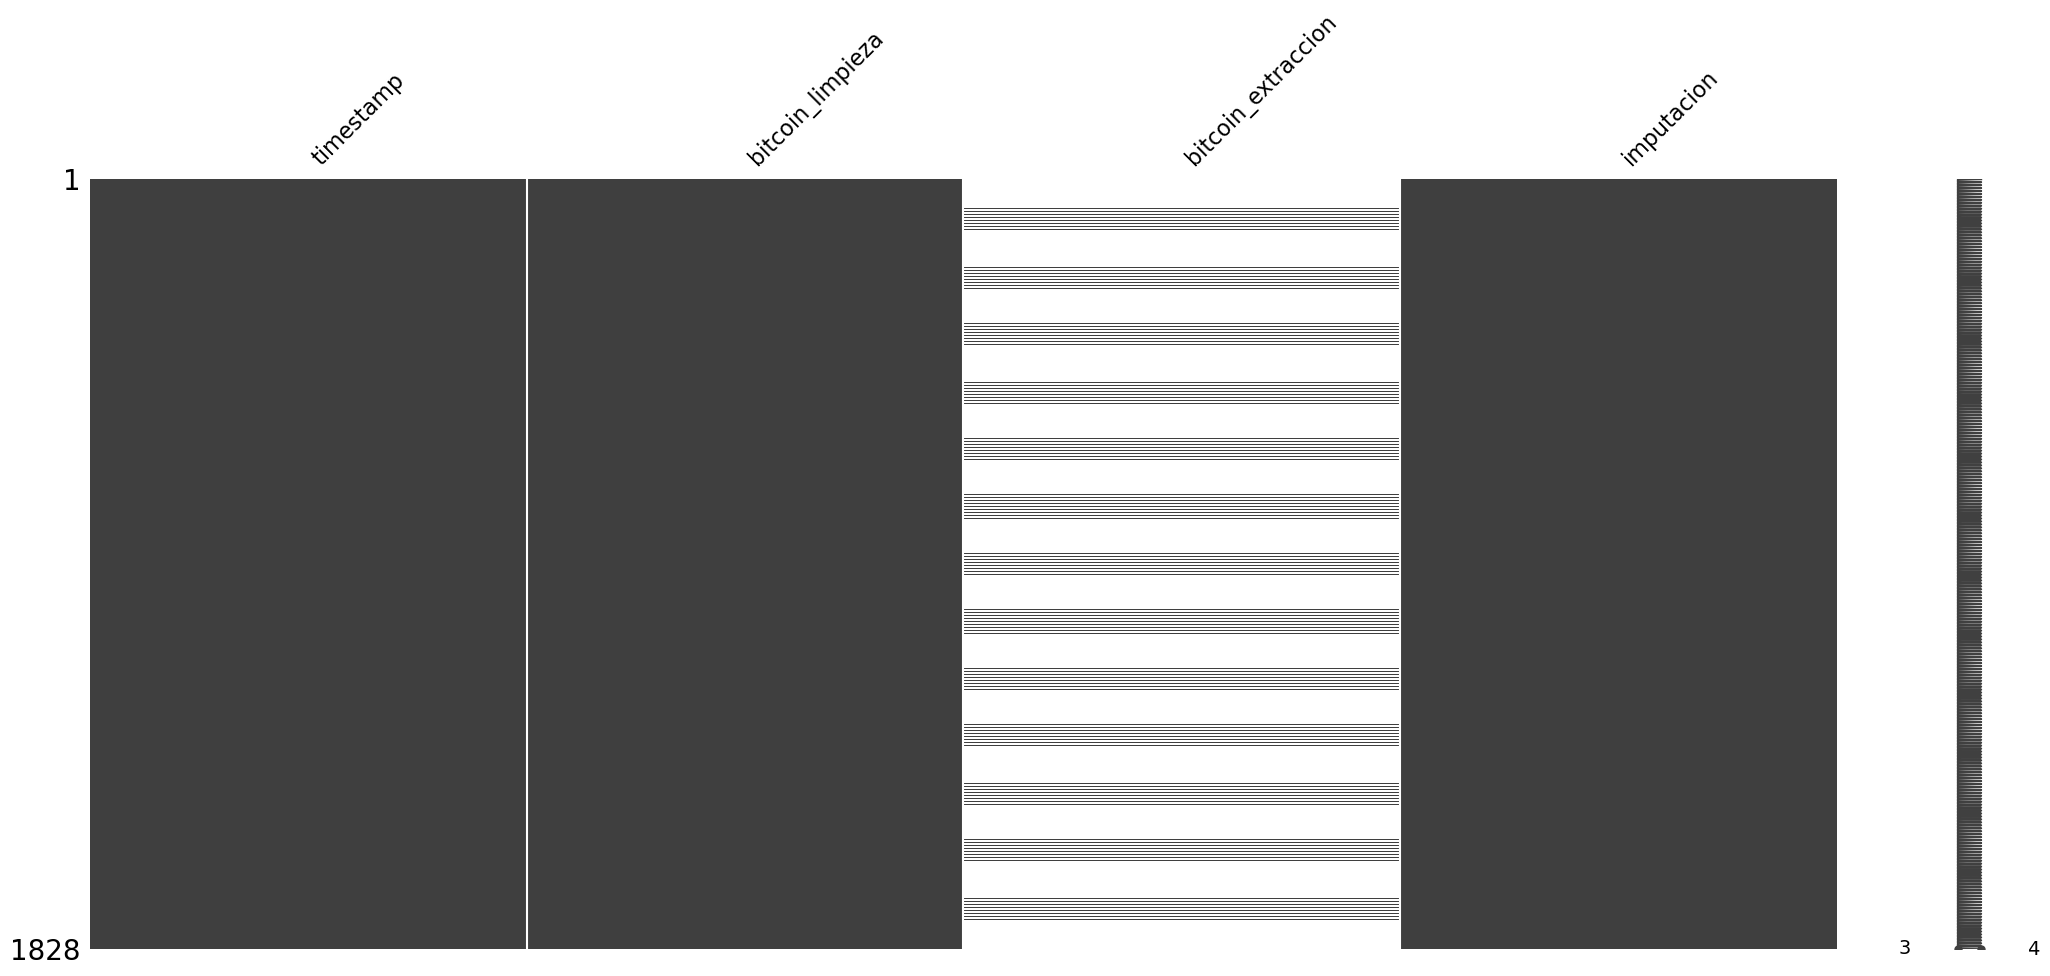

In [9]:
msno.matrix(df_combined)

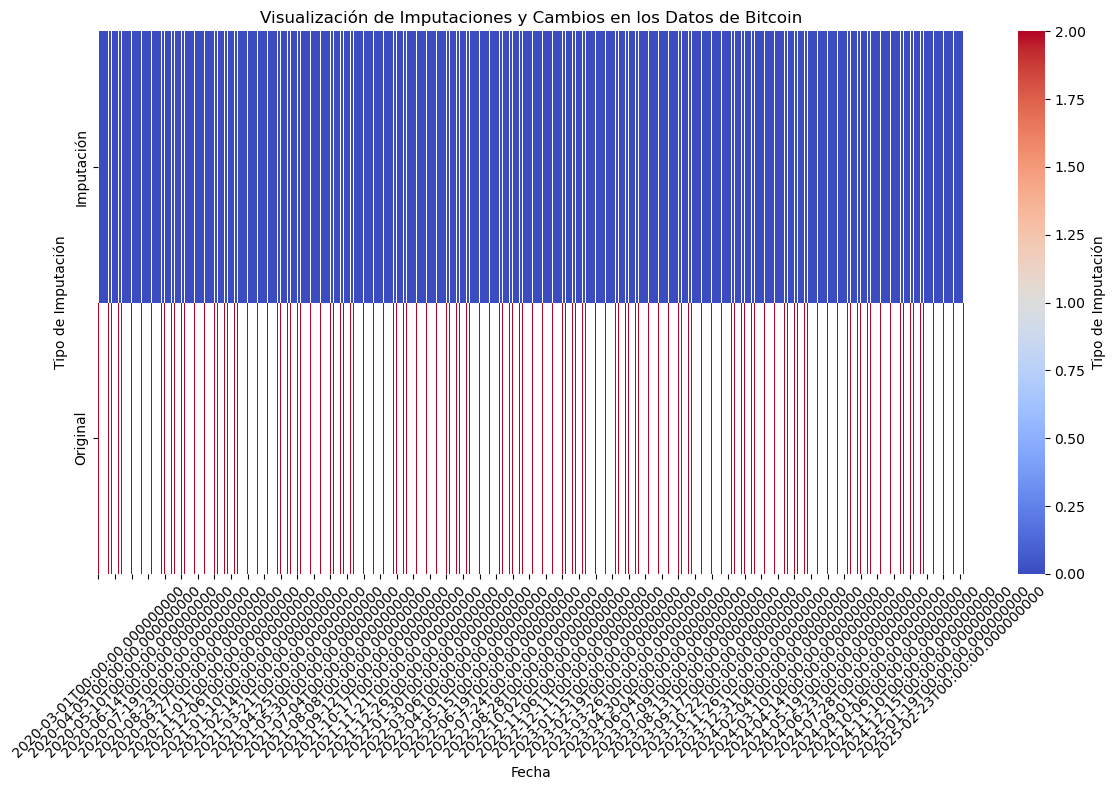

In [13]:
# Crear una columna para valores numéricos de la imputación para usar en el heatmap
df_combined['imputacion_numerica'] = df_combined['imputacion'].map({'Imputación': 0, 'Cambio': 1, 'Original': 2})

# Crear un pivot table donde las filas son las fechas y las columnas son los valores de 'imputacion_numerica'
heatmap_data = df_combined.pivot(index='timestamp', columns='imputacion', values='imputacion_numerica')

# Crear el heatmap con seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data.T, cmap="coolwarm", cbar_kws={'label': 'Tipo de Imputación'}, annot=False)

# Personalizar el gráfico
plt.title('Visualización de Imputaciones y Cambios en los Datos de Bitcoin')
plt.xlabel('Fecha')
plt.ylabel('Tipo de Imputación')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
